# RMSProp
## Polynomial Regression – Retail Store Profit Prediction

**Project:** Predicting retail store profit using Sales, Quantity, and Discount.

This notebook applies the **RMSProp optimizer** to a degree-2 Polynomial Regression model. It follows the same dataset, target, train/test split, and preprocessing approach as the previous notebooks so the optimizer results can be compared.

- **Target:** `Profit`
- **Input features:** `Sales`, `Quantity`, `Discount`
- **Polynomial degree:** 2
- **Optimizer:** RMSProp


## 1. Import Libraries

NumPy is used for mathematical operations, Pandas for data handling, Matplotlib for plots, and Scikit-learn for splitting and evaluation.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Upload and Load the Dataset

Upload `Sample - Superstore.csv` when Colab asks for the file. The `cp1252` encoding supports special characters in this dataset.

In [2]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Sample - Superstore.csv", encoding="cp1252")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Saving Sample - Superstore.csv to Sample - Superstore.csv
Dataset loaded successfully!
Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Inspect the Dataset

Check the dataset structure, missing values, duplicate rows, and numerical summary.

In [3]:
print("Dataset Information:")
df.info()

print("\\nMissing Values:")
print(df.isnull().sum())

print("\\nDuplicate Rows:")
print(df.duplicated().sum())

print("\\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


## 4. Select Features and Target

Use `Sales`, `Quantity`, and `Discount` as input features (`X`) and `Profit` as the target (`y`).

In [4]:
X = df[["Sales", "Quantity", "Discount"]]
y = df["Profit"]

print("Features:", list(X.columns))
print("Target:", y.name)


Features: ['Sales', 'Quantity', 'Discount']
Target: Profit


## 5. Split the Data

Use 80% for training and 20% for testing. `random_state=42` keeps the split consistent with the previous optimizer notebooks.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 7995
Testing samples: 1999


## 6. Generate Polynomial Features

Polynomial degree 2 adds squared terms and interaction terms to the original three features.

In [6]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

feature_names = poly.get_feature_names_out(["Sales", "Quantity", "Discount"])

print("Original Features:", X_train.shape[1])
print("Polynomial Features:", X_train_poly.shape[1])
print("Polynomial Feature Names:")
print(feature_names)


Original Features: 3
Polynomial Features: 10
Polynomial Feature Names:
['1' 'Sales' 'Quantity' 'Discount' 'Sales^2' 'Sales Quantity'
 'Sales Discount' 'Quantity^2' 'Quantity Discount' 'Discount^2']


## 7. Normalize the Input Features

Calculate the mean and range using training data only, then apply those same values to training and test data. Restore the intercept column to 1.

In [7]:
mean = X_train_poly.mean(axis=0)
range_values = X_train_poly.max(axis=0) - X_train_poly.min(axis=0)
range_values[range_values == 0] = 1

X_train_norm = (X_train_poly - mean) / range_values
X_test_norm = (X_test_poly - mean) / range_values

X_train_norm[:, 0] = 1
X_test_norm[:, 0] = 1

print("Normalization completed successfully!")
print("Training shape:", X_train_norm.shape)
print("Testing shape:", X_test_norm.shape)


Normalization completed successfully!
Training shape: (7995, 10)
Testing shape: (1999, 10)


## 8. Scale the Target Variable

Standardize `Profit` using the training target mean and standard deviation. Predictions will be converted back to the original profit scale before evaluation.

In [8]:
y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (y_train.to_numpy() - y_mean) / y_std
y_test_scaled = (y_test.to_numpy() - y_mean) / y_std

print("Target scaling completed!")


Target scaling completed!


## 9. Train Polynomial Regression Using RMSProp

**RMSProp** adapts the learning rate for each weight using a moving average of squared gradients.

For each training epoch, this notebook calculates the gradient using the full training set (batch training), updates the moving average of squared gradients, and then updates the weights.

The update equations are:

\[
S_t = \rho S_{t-1} + (1-\rho)g_t^2
\]

\[
W_t = W_{t-1} - \frac{\alpha}{\sqrt{S_t}+\epsilon}g_t
\]

Here, `rho` controls the moving average, `epsilon` prevents division by zero, and `alpha` is the base learning rate.

In [9]:
# Prepare training arrays
X_rms = X_train_norm
y_rms = y_train_scaled

m, n = X_rms.shape

# Initialize weights and squared-gradient accumulator
W_rms = np.zeros(n)
S_rms = np.zeros(n)

# RMSProp settings
learning_rate = 0.01
rho = 0.9
epsilon = 1e-8
epochs = 1000

loss_history_rms = []

# RMSProp training
for epoch in range(epochs):
    predictions = X_rms @ W_rms
    errors = predictions - y_rms

    loss = np.sum(errors ** 2) / (2 * m)
    gradient = (X_rms.T @ errors) / m

    S_rms = rho * S_rms + (1 - rho) * (gradient ** 2)
    W_rms = W_rms - (learning_rate / (np.sqrt(S_rms) + epsilon)) * gradient

    loss_history_rms.append(loss)

# Recalculate loss after the final weight update
final_predictions = X_rms @ W_rms
final_loss_rms = np.sum((final_predictions - y_rms) ** 2) / (2 * m)

print("RMSProp Training Completed!")
print("Final Loss:", final_loss_rms)


RMSProp Training Completed!
Final Loss: 0.15348268516064537


## 10. Visualize the Training Loss

The curve shows the training loss across epochs. A decreasing curve indicates that the optimizer is reducing the training error.

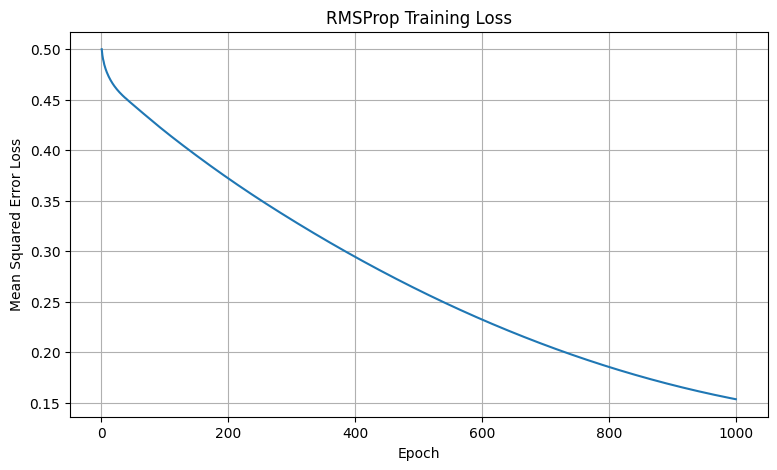

In [10]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, epochs + 1), loss_history_rms)
plt.title("RMSProp Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.grid(True)
plt.show()


## 11. Evaluate the Model

Predict profit for the test set, convert predictions back to the original scale, and calculate MSE, RMSE, MAE, and R².

In [11]:
y_pred_scaled_rms = X_test_norm @ W_rms
y_pred_rms = y_pred_scaled_rms * y_std + y_mean

mse_rms = mean_squared_error(y_test, y_pred_rms)
rmse_rms = np.sqrt(mse_rms)
mae_rms = mean_absolute_error(y_test, y_pred_rms)
r2_rms = r2_score(y_test, y_pred_rms)

print("RMSProp Results")
print("---------------")
print("MSE:", mse_rms)
print("RMSE:", rmse_rms)
print("MAE:", mae_rms)
print("R2 Score:", r2_rms)


RMSProp Results
---------------
MSE: 30113.210809716653
RMSE: 173.53158447301936
MAE: 44.73249191681663
R2 Score: 0.37891857893376424


## 12. Actual vs. Predicted Profit

This scatter plot compares actual profit values with the model predictions. Points closer to the diagonal reference line indicate more accurate predictions.

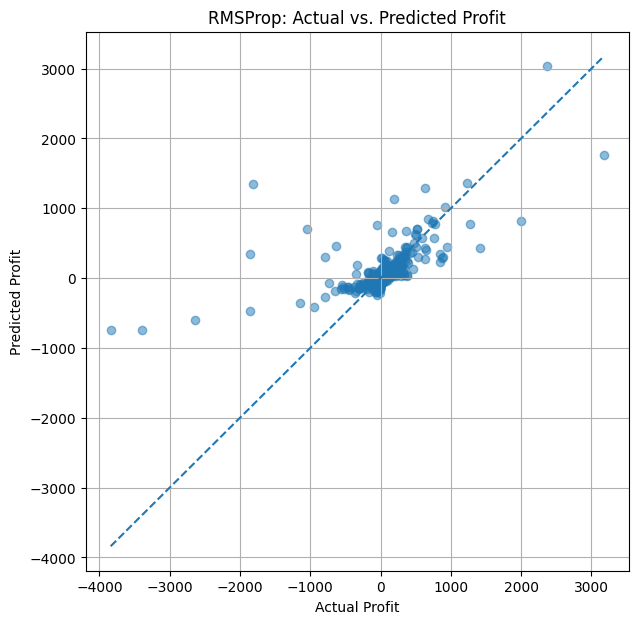

In [12]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_rms, alpha=0.5)

min_value = min(y_test.min(), y_pred_rms.min())
max_value = max(y_test.max(), y_pred_rms.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--")

plt.title("RMSProp: Actual vs. Predicted Profit")
plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")
plt.grid(True)
plt.show()


## 13. Results Summary

Keep these metrics for the final comparison of all five optimization algorithms. Lower RMSE and MAE and a higher R² generally indicate better predictions on the test set.

In [13]:
rmsprop_results = pd.DataFrame({
    "Optimizer": ["RMSProp"],
    "Final Training Loss": [final_loss_rms],
    "MSE": [mse_rms],
    "RMSE": [rmse_rms],
    "MAE": [mae_rms],
    "R2 Score": [r2_rms]
})

display(rmsprop_results)


,Optimizer,Final Training Loss,MSE,RMSE,MAE,R2 Score
0,RMSProp,0.153483,30113.21081,173.531584,44.732492,0.378919


## 14. Conclusion

In this notebook, RMSProp was implemented manually using NumPy for a degree-2 Polynomial Regression model that predicts retail store profit.

RMSProp adjusts the effective learning rate of each weight using a moving average of squared gradients. The loss curve and test metrics help assess its training behavior and predictive performance.

The final metrics will be compared with the other optimizers in the project.